# Assigment 1

In [1]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn import metrics
import numpy as np

df = pd.read_csv('uber.csv')
df.info()
to_remove_cols = ['key', 'Unnamed: 0', 'Unnamed: 0.1']
df.drop(to_remove_cols, axis=1, inplace=True)
df = df.sample(n=min(50000, len(df)), random_state=42)
df = df[
    (df['fare_amount'] > 0) &
    (df['dropoff_latitude'].between(-90, 90)) &
    (df['dropoff_longitude'].between(-180, 180)) &
    (df['pickup_latitude'].between(-90, 90)) &
    (df['pickup_longitude'].between(-180, 180)) &
    (df['passenger_count'].between(1, 6))
].copy()

df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

dt = df['pickup_datetime']
df['hour'] = dt.dt.hour
df['day'] = dt.dt.day
df['year'] = dt.dt.year
df['month'] = dt.dt.month

df.dropna(inplace=True)
df.info()

X = df.drop(['fare_amount','pickup_datetime'], axis=1).copy()
Y = df['fare_amount'].copy()
x_train, x_test, y_train, y_test = train_test_split(X, Y, random_state=42)

linear_model = LinearRegression()
linear_model.fit(x_train, y_train)
linear_model_pred = linear_model.predict(x_test)

print(metrics.r2_score(y_test, linear_model_pred))
print(np.sqrt(metrics.mean_squared_error(y_test, linear_model_pred)))

random_classifier = RandomForestRegressor(random_state=42)
random_classifier.fit(x_train, y_train)
random_classifier_predict = random_classifier.predict(x_test)
print(metrics.r2_score(y_test, random_classifier_predict))
print(np.sqrt(metrics.mean_squared_error(y_test, random_classifier_predict)))

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0.1       200000 non-null  int64  
 1   Unnamed: 0         200000 non-null  int64  
 2   key                200000 non-null  str    
 3   fare_amount        200000 non-null  float64
 4   pickup_datetime    200000 non-null  str    
 5   pickup_longitude   200000 non-null  float64
 6   pickup_latitude    200000 non-null  float64
 7   dropoff_longitude  199999 non-null  float64
 8   dropoff_latitude   199999 non-null  float64
 9   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(3), str(2)
memory usage: 15.3 MB


/tmp/ipykernel_12499/4218976785.py:11: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(to_remove_cols, axis=1, inplace=True)
/tmp/ipykernel_12499/4218976785.py:30: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


<class 'pandas.DataFrame'>
Index: 49830 entries, 119737 to 7071
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   fare_amount        49830 non-null  float64            
 1   pickup_datetime    49830 non-null  datetime64[us, UTC]
 2   pickup_longitude   49830 non-null  float64            
 3   pickup_latitude    49830 non-null  float64            
 4   dropoff_longitude  49830 non-null  float64            
 5   dropoff_latitude   49830 non-null  float64            
 6   passenger_count    49830 non-null  int64              
 7   hour               49830 non-null  int32              
 8   day                49830 non-null  int32              
 9   year               49830 non-null  int32              
 10  month              49830 non-null  int32              
dtypes: datetime64[us, UTC](1), float64(5), int32(4), int64(1)
memory usage: 3.8 MB
0.0145673173229236
10.467393956318688
0

# Assigment 2

In [2]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn import metrics

df = pd.read_csv('emails.csv')
df.describe()
df.dropna()

knn_model = KNeighborsClassifier(n_neighbors=20)

X = df.drop(['Email No.', 'Prediction'], axis=1)
Y = df['Prediction']

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=42)

knn_model.fit(x_train, y_train)
knn_predict = knn_model.predict(x_test)

print("\n--- KNN Results ---")
print("Accuracy:", metrics.accuracy_score(y_test, knn_predict))
print("Precision:", metrics.precision_score(y_test, knn_predict))
print("Recall:", metrics.recall_score(y_test, knn_predict))
print("F1 Score:", metrics.f1_score(y_test, knn_predict))
print("\nClassification Report:\n",
      metrics.classification_report(y_test, knn_predict))


from sklearn.svm import SVC

svc_model = SVC(C=1)
svc_model.fit(x_train, y_train)
svc_model_pred = svc_model.predict(x_test)
print("\n--- KNN Results ---")
print("Accuracy:", metrics.accuracy_score(y_test, svc_model_pred))
print("Precision:", metrics.precision_score(y_test, svc_model_pred))
print("Recall:", metrics.recall_score(y_test, svc_model_pred))
print("F1 Score:", metrics.f1_score(y_test, svc_model_pred))
print("\nClassification Report:\n",
      metrics.classification_report(y_test, svc_model_pred))



--- KNN Results ---
Accuracy: 0.7042525773195877
Precision: 0.47058823529411764
Recall: 0.07032967032967033
F1 Score: 0.12237093690248566

Classification Report:
               precision    recall  f1-score   support

           0       0.71      0.97      0.82      1097
           1       0.47      0.07      0.12       455

    accuracy                           0.70      1552
   macro avg       0.59      0.52      0.47      1552
weighted avg       0.64      0.70      0.62      1552


--- KNN Results ---
Accuracy: 0.7152061855670103
Precision: 0.8421052631578947
Recall: 0.035164835164835165
F1 Score: 0.06751054852320675

Classification Report:
               precision    recall  f1-score   support

           0       0.71      1.00      0.83      1097
           1       0.84      0.04      0.07       455

    accuracy                           0.72      1552
   macro avg       0.78      0.52      0.45      1552
weighted avg       0.75      0.72      0.61      1552



# Assignment 3

In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.metrics import accuracy_score, confusion_matrix

df = pd.read_csv('ch.csv')

df = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

label_encoder = LabelEncoder()

# Apply Label Encoding on 'Gender' and 'Geography'
df['Gender'] = label_encoder.fit_transform(df['Gender'])  # Female=0, Male=1
df['Geography'] = label_encoder.fit_transform(df['Geography'])  # France=0, Germany=1, Spain=2

# Separate the features and the target variables
X = df.drop('Exited', axis = 1) # Features
Y = df['Exited'] # Target

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size = 0.2)

scaler = StandardScaler()
X_train = scaler.fit_transform(x_train)
X_test = scaler.transform(x_test)

model = Sequential([
    Dense(activation='relu', units=32, input_dim=X_train.shape[1]),
    Dense(activation='relu', units=16),
    Dense(activation='sigmoid', units=1)
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])


model.fit(X_train, y_train, batch_size=100, epochs=50)

y_pred = model.predict(X_test)
y_pred = (y_pred > 0.5) # to convert the probabilistic values to True or False
y_pred

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
print("Accuracy Score:", accuracy)
print("Confusion Matrix:\n", conf_matrix)


I0000 00:00:1793677499.530026   34482 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793677499.535693   34482 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793677500.194160   34482 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793677504.896183   34482 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

Epoch 1/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7970 - loss: 0.4974
Epoch 2/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7970 - loss: 0.4418
Epoch 3/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8049 - loss: 0.4218
Epoch 4/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8314 - loss: 0.4041
Epoch 5/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8426 - loss: 0.3858
Epoch 6/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8493 - loss: 0.3709
Epoch 7/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8524 - loss: 0.3599
Epoch 8/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8554 - loss: 0.3528
Epoch 9/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8555 - loss: 0.3488
Epoch 10/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8584 - loss: 0.3452
Epoch 11/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8584 - loss: 0.3435
Epoch 12/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8587 - lo

# Assignment 4

In [3]:
#  • B4: Implement Gradient Descent to find a local minimum of y = (x + 3)² starting at x = 2. 


x = 2
learning_rate = 0.0001
max_iterations = 10000

for i in range(max_iterations):
    y = (x + 3) ** 2
    drrivative = 2 * (x + 3)
    print(f"Iteration {i + 1}: x = {x:.4f}, y = {y:.4f}, Gradient = {drrivative:.4f}")
    x = x - learning_rate * drrivative

print(f"\nMinimum x = {x:.4f}")
print(f"Minimum y = {(x + 3) ** 2:.4f}")


Iteration 1: x = 2.0000, y = 25.0000, Gradient = 10.0000
Iteration 2: x = 1.9990, y = 24.9900, Gradient = 9.9980
Iteration 3: x = 1.9980, y = 24.9800, Gradient = 9.9960
Iteration 4: x = 1.9970, y = 24.9700, Gradient = 9.9940
Iteration 5: x = 1.9960, y = 24.9600, Gradient = 9.9920
Iteration 6: x = 1.9950, y = 24.9500, Gradient = 9.9900
Iteration 7: x = 1.9940, y = 24.9401, Gradient = 9.9880
Iteration 8: x = 1.9930, y = 24.9301, Gradient = 9.9860
Iteration 9: x = 1.9920, y = 24.9201, Gradient = 9.9840
Iteration 10: x = 1.9910, y = 24.9102, Gradient = 9.9820
Iteration 11: x = 1.9900, y = 24.9002, Gradient = 9.9800
Iteration 12: x = 1.9890, y = 24.8902, Gradient = 9.9780
Iteration 13: x = 1.9880, y = 24.8803, Gradient = 9.9760
Iteration 14: x = 1.9870, y = 24.8703, Gradient = 9.9740
Iteration 15: x = 1.9860, y = 24.8604, Gradient = 9.9720
Iteration 16: x = 1.9850, y = 24.8504, Gradient = 9.9700
Iteration 17: x = 1.9840, y = 24.8405, Gradient = 9.9680
Iteration 18: x = 1.9830, y = 24.8306, 

# Assignment 5

/tmp/ipykernel_12499/1579076629.py:8: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


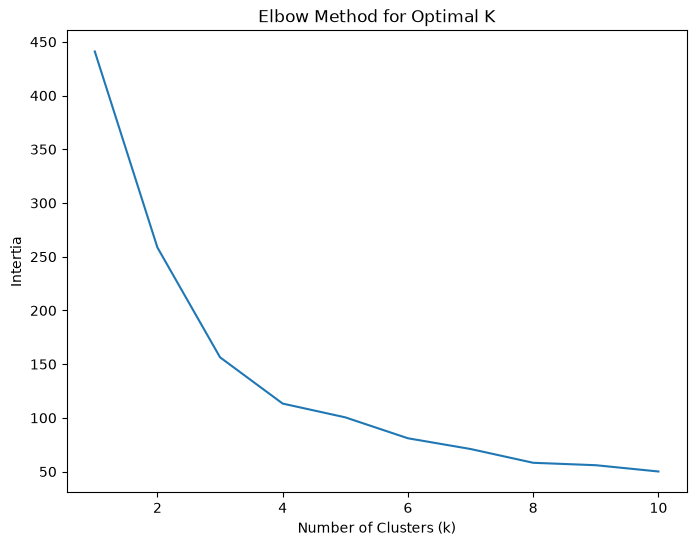

In [4]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

df = pd.read_csv('sales_data_sample.csv')
df.dropna(inplace=True)

X = df[['SALES', 'QUANTITYORDERED', 'PRICEEACH']]

scaler = StandardScaler()

x_scaled = scaler.fit_transform(X)

inertia = []

K = range(1, 11)


for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(x_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 6))
plt.plot(K, inertia)
plt.xlabel('Number of Clusters (k)')
plt.ylabel("Intertia")

plt.title("Elbow Method for Optimal K")
plt.show()

# Choose k based on elbow point (e.g., k=4)
optimal_k = 4

kmeans = KMeans(n_clusters=optimal_k, random_state=42)
df['Cluster'] = kmeans.fit_predict(x_scaled)

# Check cluster assignments
df[['SALES', 'QUANTITYORDERED', 'PRICEEACH', 'Cluster']]

df.to_csv("Shrihari.csv")
